In [9]:
import numpy as np
import pandas as pd

x_crop = np.load("x_crop.npy") 
x_ctx  = np.load("x_ctx.npy")
df = pd.read_csv("df_with_paths.csv")
y = df["label"].values
print(x_crop.shape, x_ctx.shape, len(df))

(1696, 1, 224, 224) (1696, 1, 224, 224) 1696


In [10]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from torchvision import tv_tensors
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Training on:", device)

Training on: cuda


In [11]:
is_train = (df["split"] == "train").values
is_val   = (df["split"] == "val").values

# augmentation that is only applied for the training split only 
train_aug = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomVerticalFlip(),
    v2.RandomAffine(degrees=25, scale=(0.8, 1.2)),   # rotation +/-25 degrees, zoom 0.8-1.2
    v2.ColorJitter(brightness=0.2),                  # brightness shift
])
# ResNet-18 was pretrained on ImageNet, so I use ImageNet's mean and std to normalize
to_resnet = v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

class PairDataset(Dataset):
    def __init__(self, x_crop, x_ctx, y, augment=False):
        self.x_crop = torch.from_numpy(x_crop)
        self.x_ctx = torch.from_numpy(x_ctx)
        self.y = torch.from_numpy(y).float()
        self.augment = augment
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        crop = tv_tensors.Image(self.x_crop[i])
        ctx = tv_tensors.Image(self.x_ctx[i])
        if self.augment:
            crop, ctx = train_aug(crop, ctx)          # same random transform for crop and context
        crop = to_resnet(crop.repeat(3, 1, 1)).as_subclass(torch.Tensor)   # grey -> 3 channels
        ctx = to_resnet(ctx.repeat(3, 1, 1)).as_subclass(torch.Tensor)
        return crop, ctx, self.y[i]

train_ds = PairDataset(x_crop[is_train], x_ctx[is_train], y[is_train], augment=True)
val_ds   = PairDataset(x_crop[is_val],   x_ctx[is_val],   y[is_val])
print("train:", len(train_ds), "| val:", len(val_ds))

train: 1177 | val: 350


In [12]:
class TwoStreamNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.name = "twostream"
        # Two pretrained ResNet-18
        resnet_a = models.resnet18(weights=models.ResNet18_Weights.DEFAULT) # stream 1 sees the crop
        resnet_b = models.resnet18(weights=models.ResNet18_Weights.DEFAULT) # stream 2 sees the context window
        self.stream1_features = nn.Sequential(*list(resnet_a.children())[:-2])   # remove pool + fc
        self.stream2_features = nn.Sequential(*list(resnet_b.children())[:-2])

        # 2. Freeze both streams (transfer learning, no fine-tuning)
        for param in self.stream1_features.parameters():
            param.requires_grad = False
        for param in self.stream2_features.parameters():
            param.requires_grad = False

        # 3. Pool each 7x7x512 feature map to 512 numbers
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # 4. Classifier on the joined features (the only part that trains)
        self.classifier = nn.Sequential(
            nn.Linear(512 + 512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
        )

    def forward(self, crop, context):
        vec1 = torch.flatten(self.pool(self.stream1_features(crop)), 1)      # [B, 512]
        vec2 = torch.flatten(self.pool(self.stream2_features(context)), 1)   # [B, 512]
        fused = torch.cat((vec1, vec2), dim=1)                               # [B, 1024]
        return self.classifier(fused).squeeze(1)                            # [B]

In [ ]:
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay 

METRICS = ["loss", "auroc", "accuracy", "sensitivity", "specificity", "precision", "f1"]

def compute_metrics(labels, probs, threshold=0.5):
    """All success metrics (and confusion-matrix counts) from true labels and predicted probabilities."""
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0     # malignant masses caught
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0     # benign masses correctly cleared
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0       # "malignant" predictions that are right
    f1 = 2 * precision * sensitivity / (precision + sensitivity) if (precision + sensitivity) > 0 else 0.0
    return {"auroc": roc_auc_score(labels, probs),
            "accuracy": (tp + tn) / len(labels),
            "sensitivity": sensitivity, "specificity": specificity,
            "precision": precision, "f1": f1,
            "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn)}

In [17]:
def evaluate(net, loader, criterion):
    """Loss and all success metrics on a dataset, without training."""
    net.eval()
    total_loss, total = 0.0, 0
    all_probs, all_labels = [], []
    with torch.no_grad():
        for crops, ctxs, labels in loader:
            crops, ctxs, labels = crops.to(device), ctxs.to(device), labels.to(device)
            outputs = net(crops, ctxs)
            total_loss += criterion(outputs, labels).item() * len(labels)
            total += len(labels)
            all_probs.append(torch.sigmoid(outputs).cpu()); all_labels.append(labels.cpu())
    results = compute_metrics(torch.cat(all_labels).numpy(), torch.cat(all_probs).numpy())
    results["loss"] = total_loss / total
    return results

def train_net(net, train_ds, val_ds, batch_size=16, learning_rate=0.001, num_epochs=10):
    torch.manual_seed(1)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=0)

    # class-weighted BCE: malignant errors weighted by #benign / #malignant
    n_pos = train_ds.y.sum().item()
    n_neg = len(train_ds) - n_pos
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg / n_pos], device=device))
    optimizer = optim.Adam(net.classifier.parameters(), lr=learning_rate)   # only the classifier trains

    history = {"train": [], "val": []}          # one dictionary of results per epoch
    start_time = time.time()
    for epoch in range(num_epochs):
        # --- train ---
        net.train()
        net.stream1_features.eval()             # frozen streams stay fully frozen
        net.stream2_features.eval()
        for crops, ctxs, labels in train_loader:
            crops, ctxs, labels = crops.to(device), ctxs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = net(crops, ctxs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        # --- measure on train and validation ---
        train_res = evaluate(net, train_loader, criterion)
        val_res = evaluate(net, val_loader, criterion)
        history["train"].append(train_res)
        history["val"].append(val_res)
        print("Epoch {}: Train AUROC {:.3f}, loss {:.3f} | Val AUROC {:.3f}, loss {:.3f}".format(
            epoch + 1, train_res["auroc"], train_res["loss"], val_res["auroc"], val_res["loss"]))

    print("Finished training in {:.1f} seconds".format(time.time() - start_time))
    return history


MODEL_NAME = "twostream"
model = TwoStreamNet().to(device)        # fresh model every time you run this cell
print("trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))   # 262,657
print("total parameters:", sum(p.numel() for p in model.parameters()))                          # 22,615,681
history = train_net(model, train_ds, val_ds, batch_size=16, learning_rate=0.001, num_epochs=10)

trainable parameters: 262657
total parameters: 22615681
Epoch 1: Train AUROC 0.687, loss 0.761 | Val AUROC 0.778, loss 0.713
Epoch 2: Train AUROC 0.750, loss 0.697 | Val AUROC 0.781, loss 0.685
Epoch 3: Train AUROC 0.740, loss 0.667 | Val AUROC 0.787, loss 0.641
Epoch 4: Train AUROC 0.744, loss 0.721 | Val AUROC 0.790, loss 0.692
Epoch 5: Train AUROC 0.765, loss 0.676 | Val AUROC 0.785, loss 0.640
Epoch 6: Train AUROC 0.763, loss 0.663 | Val AUROC 0.790, loss 0.626
Epoch 7: Train AUROC 0.778, loss 0.628 | Val AUROC 0.791, loss 0.614
Epoch 8: Train AUROC 0.771, loss 0.643 | Val AUROC 0.790, loss 0.606
Epoch 9: Train AUROC 0.770, loss 0.637 | Val AUROC 0.797, loss 0.596
Epoch 10: Train AUROC 0.776, loss 0.649 | Val AUROC 0.798, loss 0.611
Finished training in 132.9 seconds


Best epoch (highest validation AUROC): 10
             train  validation
loss         0.649       0.611
auroc        0.776       0.798
accuracy     0.661       0.677
sensitivity  0.861       0.837
specificity  0.493       0.533
precision    0.588       0.618
f1           0.699       0.711


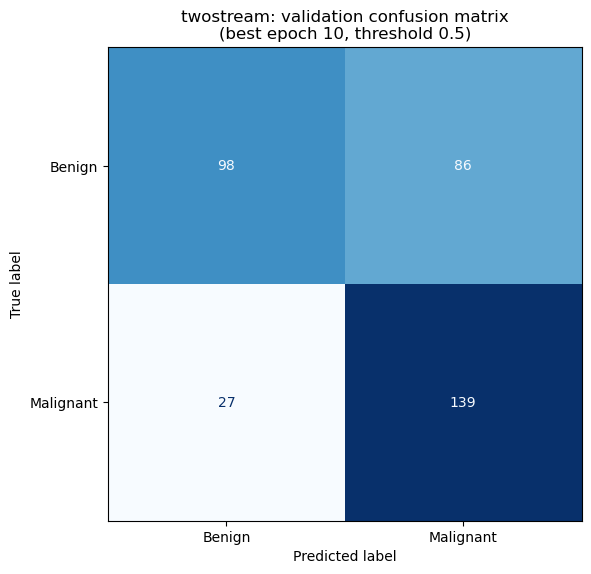

In [18]:
val_aurocs = [r["auroc"] for r in history["val"]]
best = int(np.argmax(val_aurocs))                          # AUROC picks the epoch
best_val = history["val"][best]
best_train = history["train"][best]

print("Best epoch (highest validation AUROC):", best + 1)
results = pd.DataFrame({"train": [best_train[m] for m in METRICS],
                        "validation": [best_val[m] for m in METRICS]}, index=METRICS)
print(results.round(3).to_string())
results.to_csv("{}_results.csv".format(MODEL_NAME))       # saved for comparing with the baseline

# confusion matrix of that same epoch
cm = np.array([[best_val["tn"], best_val["fp"]],
               [best_val["fn"], best_val["tp"]]])
disp = ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("{}: validation confusion matrix\n(best epoch {}, threshold 0.5)".format(MODEL_NAME, best + 1))
plt.tight_layout(); plt.savefig("{}_confusion_matrix.png".format(MODEL_NAME), dpi=150); plt.show()

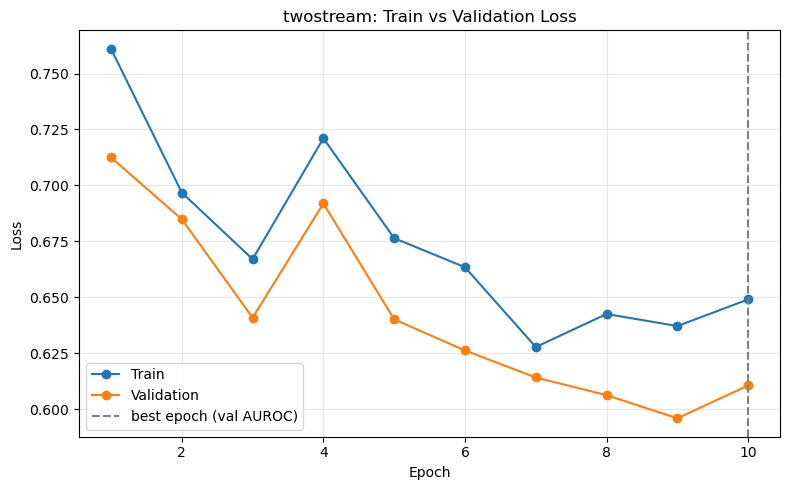

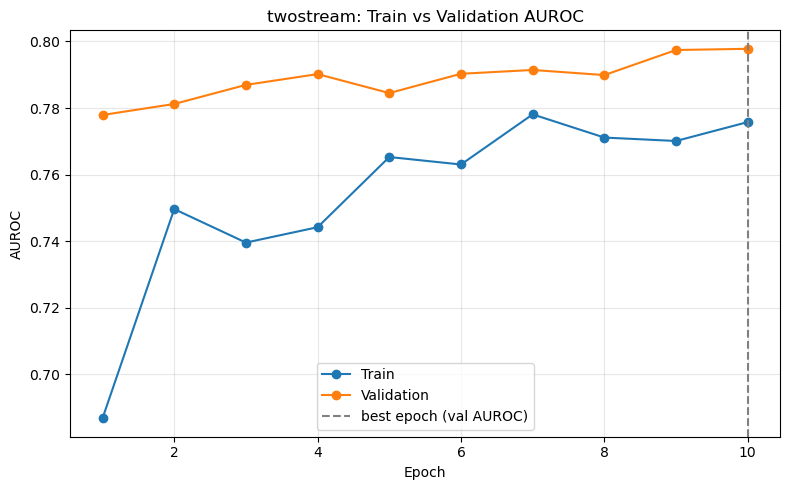

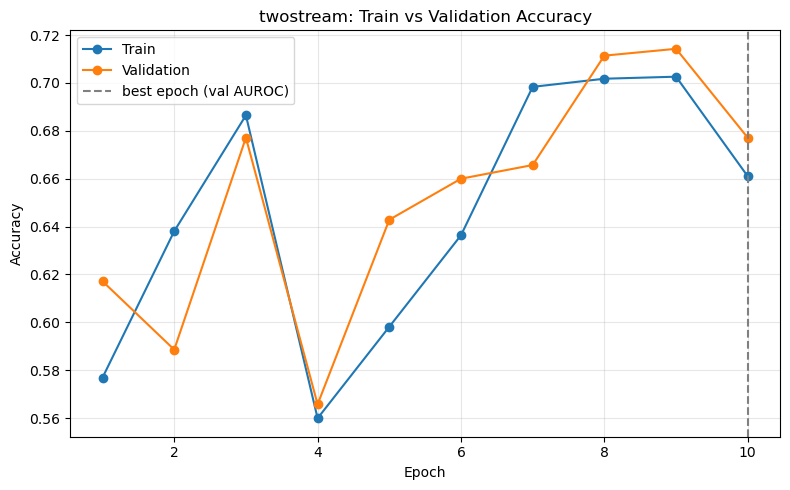

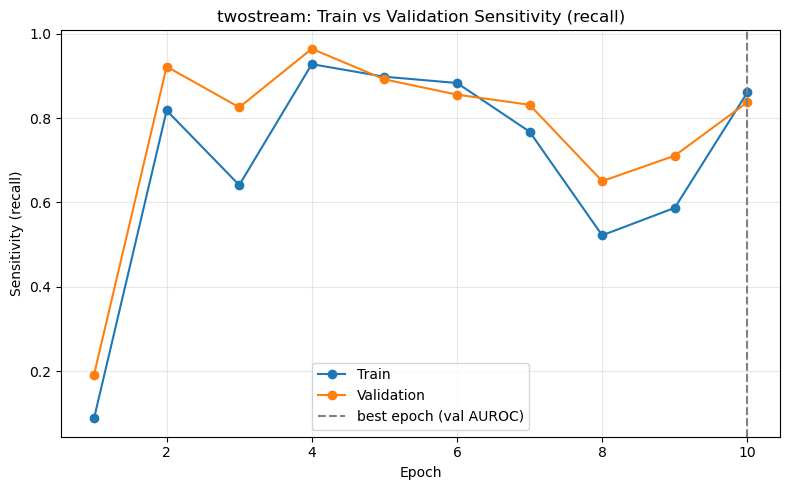

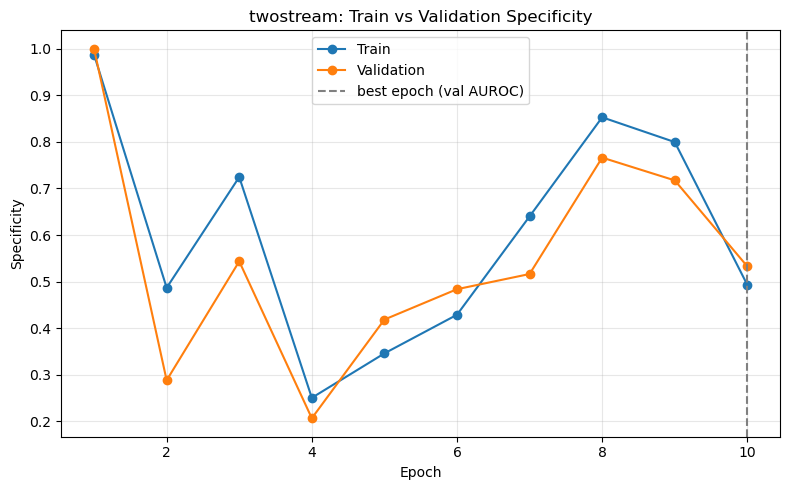

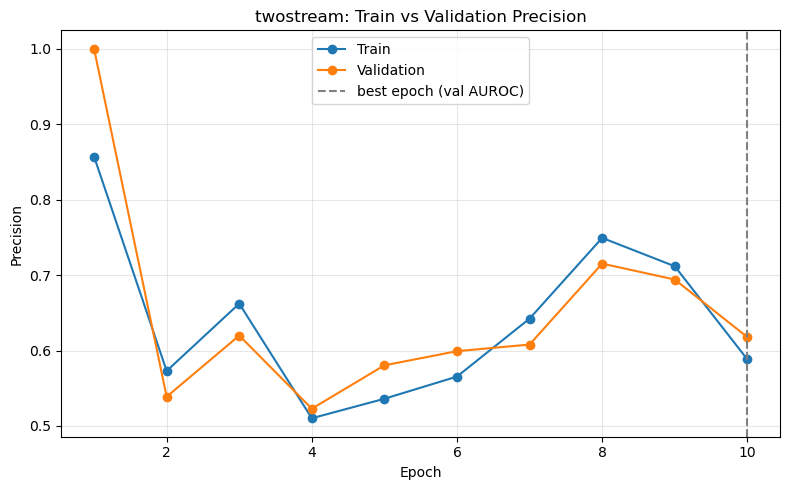

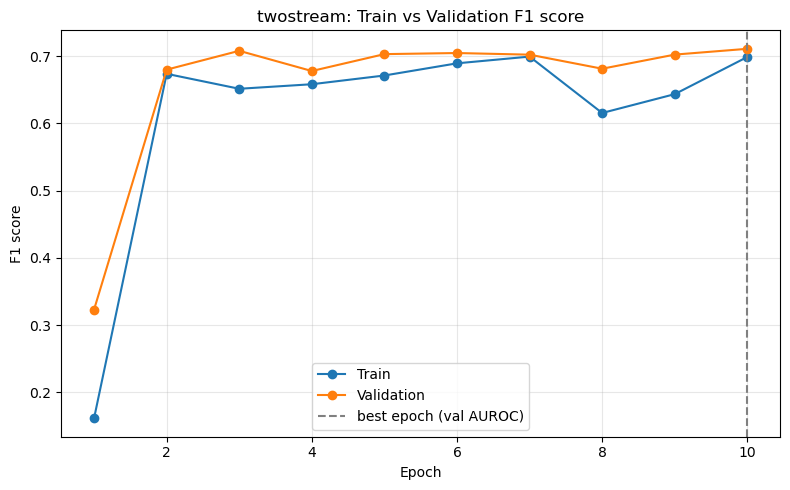

In [19]:
epochs = range(1, len(history["train"]) + 1)
titles = {"loss": "Loss", "auroc": "AUROC", "accuracy": "Accuracy", "sensitivity": "Sensitivity (recall)",
          "specificity": "Specificity", "precision": "Precision", "f1": "F1 score"}

for m in METRICS:
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, [r[m] for r in history["train"]], marker="o", label="Train")
    plt.plot(epochs, [r[m] for r in history["val"]], marker="o", label="Validation")
    plt.axvline(best + 1, color="gray", linestyle="--", label="best epoch (val AUROC)")
    plt.title("{}: Train vs Validation {}".format(MODEL_NAME, titles[m]))
    plt.xlabel("Epoch"); plt.ylabel(titles[m])
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
    plt.savefig("{}_{}.png".format(MODEL_NAME, m), dpi=150); plt.show()

In [20]:
print("=" * 60)
print("{}  |  best epoch: {} of {}  (chosen by validation AUROC)".format(
    MODEL_NAME, best + 1, len(history["val"])))
print("Validation AUROC {:.3f} | accuracy {:.3f} | sensitivity {:.3f} | specificity {:.3f} | F1 {:.3f}".format(
    best_val["auroc"], best_val["accuracy"], best_val["sensitivity"], best_val["specificity"], best_val["f1"]))
print("=" * 60)

twostream  |  best epoch: 10 of 10  (chosen by validation AUROC)
Validation AUROC 0.798 | accuracy 0.677 | sensitivity 0.837 | specificity 0.533 | F1 0.711


In [21]:
mlp = pd.read_csv("mlp_results.csv", index_col=0)["validation"]
two = pd.read_csv("twostream_results.csv", index_col=0)["validation"]
comparison = pd.DataFrame({"MLP baseline": mlp, "Two-stream CNN": two})
print(comparison.round(3).to_string())
print("Higher validation AUROC:", comparison.loc["auroc"].idxmax())

             MLP baseline  Two-stream CNN
loss                0.723           0.611
auroc               0.658           0.798
accuracy            0.551           0.677
sensitivity         0.801           0.837
specificity         0.326           0.533
precision           0.518           0.618
f1                  0.629           0.711
Higher validation AUROC: Two-stream CNN
